# NLP Mini Project

Pre-processer text (cleaning, tokenization, normalization) - regex?
lav vocabulary (brug tokenization)

vectorize text - ngram LMs - should preprocessing be the same for (1) and (2)?

Raw text
  ↓
Cleaning
  ↓
Tokenization
  ↓
Normalization
  ↓
Vocabulary / linguistic analysis
  ↓
Feature extraction
  ↓
Classifier
  ↓
Prediction

## DATA

In [1]:
import pandas as pd

df = pd.read_json("train.jsonl", lines=True)

df.head()

,id,text,model,label,genre
0,ea468d03-1973-5039-86b2-ff225bb92c4e,"Duke Ellington, a titan of jazz, revolutionize...",falcon3-10b-instruct,1,essays
1,0d05f269-6d67-521d-9b5d-cc18f482c6c1,I reflected on the shifting dynamics of media ...,o3-mini,1,essays
2,c2ec79f3-da80-58f8-bef0-3e0ea7ab072f,"In F. Scott Fitzgerald's ""The Great Gatsby,"" t...",gpt-4o,1,essays
3,4ad37c58-0bb7-536b-997d-cfccabd0d094,I still chuckle when I think about that time I...,deepseek-r1-distill-qwen-32b,1,essays
4,07747b0c-5051-5e0d-8096-b4d4ed8bd98e,"Yoga, originating in ancient India, encompasse...",gemini-2.0-flash,1,essays


In [2]:
df["model"].value_counts()

model
human                           9101
gpt-3.5-turbo                   1374
gpt-4o-mini                     1358
gpt-4o                          1336
ministral-8b-instruct-2410      1100
gemini-2.0-flash                1079
o3-mini                         1075
gemini-1.5-pro                  1072
llama-3.1-8b-instruct           1063
deepseek-r1-distill-qwen-32b     901
falcon3-10b-instruct             879
llama-3.3-70b-instruct           405
gpt-4.5-preview                  278
gpt-4-turbo-paraphrase           276
gemini-pro                       276
gpt-4-turbo                      272
qwen1.5-72b-chat-8bit            271
llama-2-70b-chat                 269
mistral-7b-instruct-v0.2         266
gemini-pro-paraphrase            265
text-bison-002                   265
mixtral-8x7b-instruct-v0.1       264
llama-2-7b-chat                  262
Name: count, dtype: int64

In [3]:
df["label"].value_counts()

label
1    14606
0     9101
Name: count, dtype: int64

In [4]:
df["genre"].value_counts()

genre
fiction    14697
essays      4661
news        4349
Name: count, dtype: int64

In [5]:
print(df["text"][0])

Duke Ellington, a titan of jazz, revolutionized the genre through his innovative compositions, showcasing a remarkable ability to integrate voice and instrumental music. Among the notable figures who contributed to this artistic symphony was Ivie Anderson, whose scat singing mirrored the improvisational prowess of musicians like Nanton. In "Ring Dem Bells," Ellington ingeniously interweaves scat singing as a dialogue with saxophones, creating a dynamic call and response that underscores his vision of music as a fluid conversation between voices and instruments.

Ellington consistently emphasized the voice as an instrument of equal importance to traditional brass and woodwinds, orchestrating his compositions with a keen ear for vocal qualities. This approach is vividly demonstrated in "Mood Indigo," where his orchestration skills shine through non-traditional chord arrangements, transforming the piece into an auditory tapestry of mood and color. It is not merely the notes that define El

## 1 Statistical model with linguistic features

Lav et datasæt: f_1, f_2, genre, label

- Måske med model type også


Features:
- Count words
- Count punctuations
- POS: count each word class
- POS: count n-gram combinations

Note: Gør flere ting til frekevnser. Især POS counts. Det er mere sigende hvor mange navneord der er ifht. tekst længde, end det faktiske antal navneord. 


In [6]:
import spacy
from itertools import product
from spacy.parts_of_speech import IDS
nlp = spacy.load("en_core_web_sm")


In [7]:
def preprocess_text(text):
    doc = nlp(text)
    tokens = [token.lemma_.lower() for token in doc if not token.is_stop and not token.is_punct]
    print(tokens)

# Count the number of tokens in the text after preprocessing
def count_tokens(text):
    doc = nlp(text)
    tokens = [token.lemma_.lower() for token in doc if not token.is_stop and not token.is_punct]
    return len(tokens)

# Count the number of punctuation marks in the text
def count_punctuation(text):
    doc = nlp(text)
    punctuation_count = sum(1 for token in doc if token.is_punct)
    return punctuation_count

# count the number of stopwords in the text
def count_stopwords(text):
    doc = nlp(text)
    stopword_count = sum(1 for token in doc if token.is_stop)
    return stopword_count
# Alle navngivne POS-tags; udelad den tomme label
POS_TAGS = sorted(tag for tag in IDS if tag)


# Count number of POS tags in the text
def count_pos_tags(text):
    doc = nlp(text)

    # Start alle tags på 0
    pos_counts = {pos: 0 for pos in POS_TAGS}

    for token in doc:
        pos_counts[token.pos_] += 1

    return pos_counts


# Count number of POS bigram tags in the text
def count_pos_bigrams(text):
    doc = nlp(text)

    # Start alle mulige ordnede par på 0
    pos_bigrams = {
        bigram: 0
        for bigram in product(POS_TAGS, repeat=2)
    }

    for i in range(len(doc) - 1):
        bigram = (doc[i].pos_, doc[i + 1].pos_)
        pos_bigrams[bigram] += 1

    return pos_bigrams

In [8]:
count_tokens(df["text"][0])


223

In [9]:
count_punctuation(df["text"][0])

56

In [10]:
count_stopwords(df["text"][0])

147

In [11]:
count_pos_tags(df["text"][0])

{'ADJ': 32,
 'ADP': 49,
 'ADV': 10,
 'AUX': 4,
 'CCONJ': 15,
 'CONJ': 0,
 'DET': 40,
 'EOL': 0,
 'INTJ': 0,
 'NOUN': 108,
 'NUM': 0,
 'PART': 10,
 'PRON': 21,
 'PROPN': 27,
 'PUNCT': 55,
 'SCONJ': 7,
 'SPACE': 3,
 'SYM': 0,
 'VERB': 45,
 'X': 0}

In [12]:
count_pos_bigrams(df["text"][0])

{('ADJ', 'ADJ'): 2,
 ('ADJ', 'ADP'): 3,
 ('ADJ', 'ADV'): 0,
 ('ADJ', 'AUX'): 0,
 ('ADJ', 'CCONJ'): 0,
 ('ADJ', 'CONJ'): 0,
 ('ADJ', 'DET'): 0,
 ('ADJ', 'EOL'): 0,
 ('ADJ', 'INTJ'): 0,
 ('ADJ', 'NOUN'): 27,
 ('ADJ', 'NUM'): 0,
 ('ADJ', 'PART'): 0,
 ('ADJ', 'PRON'): 0,
 ('ADJ', 'PROPN'): 0,
 ('ADJ', 'PUNCT'): 0,
 ('ADJ', 'SCONJ'): 0,
 ('ADJ', 'SPACE'): 0,
 ('ADJ', 'SYM'): 0,
 ('ADJ', 'VERB'): 0,
 ('ADJ', 'X'): 0,
 ('ADP', 'ADJ'): 5,
 ('ADP', 'ADP'): 0,
 ('ADP', 'ADV'): 0,
 ('ADP', 'AUX'): 0,
 ('ADP', 'CCONJ'): 0,
 ('ADP', 'CONJ'): 0,
 ('ADP', 'DET'): 13,
 ('ADP', 'EOL'): 0,
 ('ADP', 'INTJ'): 0,
 ('ADP', 'NOUN'): 14,
 ('ADP', 'NUM'): 0,
 ('ADP', 'PART'): 0,
 ('ADP', 'PRON'): 7,
 ('ADP', 'PROPN'): 2,
 ('ADP', 'PUNCT'): 5,
 ('ADP', 'SCONJ'): 1,
 ('ADP', 'SPACE'): 0,
 ('ADP', 'SYM'): 0,
 ('ADP', 'VERB'): 2,
 ('ADP', 'X'): 0,
 ('ADV', 'ADJ'): 0,
 ('ADV', 'ADP'): 1,
 ('ADV', 'ADV'): 0,
 ('ADV', 'AUX'): 0,
 ('ADV', 'CCONJ'): 0,
 ('ADV', 'CONJ'): 0,
 ('ADV', 'DET'): 1,
 ('ADV', 'EOL'): 0,
 ('ADV

## Data fordeling

Er der forskel i hvordan de ovenstående punkter fordeler sig alt efter om det er menneske eller maskine?


In [13]:
import numpy as np
import pandas as pd

feature_rows = []

docs = nlp.pipe(
    df["text"],
    batch_size=128,
    disable=nlp.pipe_names,
)

for doc in docs:
    tokens = [token for token in doc if not token.is_space]
    word_tokens = [token for token in tokens if not token.is_punct]

    n_tokens = len(tokens)
    n_word_tokens = len(word_tokens)
    n_characters = len(doc.text)

    n_stopwords = sum(token.is_stop for token in word_tokens)
    n_punctuation = sum(token.is_punct for token in tokens)

    feature_rows.append({
        # Andel stopord blandt ordtokens
        "stopword_ratio": (
            n_stopwords / n_word_tokens if n_word_tokens else np.nan
        ),

        # Andel tegnsætning blandt alle tokens uden whitespace
        "punctuation_ratio": (
            n_punctuation / n_tokens if n_tokens else np.nan
        ),

        "count_characters": n_characters,

        # Samlet tekstlængde divideret med antal tokens uden whitespace
        "characters_per_token": (
            n_characters / n_tokens if n_tokens else np.nan
        ),

        "count_tokens": sum(
            not token.is_stop and not token.is_punct
            for token in doc
        ),
    })

# Bevar samme rækkeindeks som df
feature_df = pd.DataFrame(feature_rows, index=df.index)

# Fjern de gamle kolonnenavne, hvis de findes
df = df.drop(
    columns=["count_stopwords", "count_punctuation"],
    errors="ignore",
)

# Tilføj featurekolonnerne til df
df[feature_df.columns] = feature_df

In [14]:
df.head()

,id,text,model,label,genre,stopword_ratio,punctuation_ratio,count_characters,characters_per_token,count_tokens
0,ea468d03-1973-5039-86b2-ff225bb92c4e,"Duke Ellington, a titan of jazz, revolutionize...",falcon3-10b-instruct,1,essays,0.400545,0.132388,2480,5.862884,223
1,0d05f269-6d67-521d-9b5d-cc18f482c6c1,I reflected on the shifting dynamics of media ...,o3-mini,1,essays,0.439539,0.081129,3395,5.987654,295
2,c2ec79f3-da80-58f8-bef0-3e0ea7ab072f,"In F. Scott Fitzgerald's ""The Great Gatsby,"" t...",gpt-4o,1,essays,0.438356,0.105079,3288,5.758319,292
3,4ad37c58-0bb7-536b-997d-cfccabd0d094,I still chuckle when I think about that time I...,deepseek-r1-distill-qwen-32b,1,essays,0.564835,0.109589,2347,4.592955,201
4,07747b0c-5051-5e0d-8096-b4d4ed8bd98e,"Yoga, originating in ancient India, encompasse...",gemini-2.0-flash,1,essays,0.388258,0.159236,3588,5.713376,327


In [15]:
import numpy as np
import matplotlib.pyplot as plt

def plot_feature_distribution(df, feature_name, bins=30):
    # Beregn statistik for hver gruppe
    statistics = (
        df.groupby("label")[feature_name]
        .agg(
            Antal="count",
            Gennemsnit="mean",
            Median="median",
            Standardafvigelse="std",
            Minimum="min",
            Maksimum="max",
            Antal_nuller=lambda values: values.eq(0).sum(),
            Nuller_procent=lambda values: (
                100 * values.dropna().eq(0).mean()
            ),
        )
        .rename(index={0: "Menneske", 1: "Maskine"})
    )

    print(f"\nStatistik for {feature_name}:")
    print(statistics.T.round(3).to_string())

    # Samme intervaller for begge grupper
    bin_edges = np.histogram_bin_edges(
        df[feature_name].dropna(),
        bins=bins,
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    for label, navn, farve in [
        (0, "Menneske", "steelblue"),
        (1, "Maskine", "darkorange"),
    ]:
        values = df.loc[df["label"] == label, feature_name].dropna()

        if values.empty:
            continue

        # Hver gruppe summerer til 100 %
        weights = np.ones(len(values)) * 100 / len(values)

        ax.hist(
            values,
            bins=bin_edges,
            weights=weights,
            alpha=0.5,
            color=farve,
            label=f"{navn} (n={len(values)})",
        )

    ax.set_xlabel(feature_name)
    ax.set_ylabel("Andel af gruppens tekster (%)")
    ax.set_title(f"Fordeling af {feature_name}: Menneske og Maskine")

    if ax.has_data():
        ax.legend()

    fig.tight_layout()
    plt.show()

    return statistics


Statistik for stopword_ratio:
label              Menneske    Maskine
Antal              9101.000  14606.000
Gennemsnit            0.569      0.474
Median                0.576      0.481
Standardafvigelse     0.054      0.061
Minimum               0.312      0.009
Maksimum              0.723      0.695
Antal_nuller          0.000      0.000
Nuller_procent        0.000      0.000


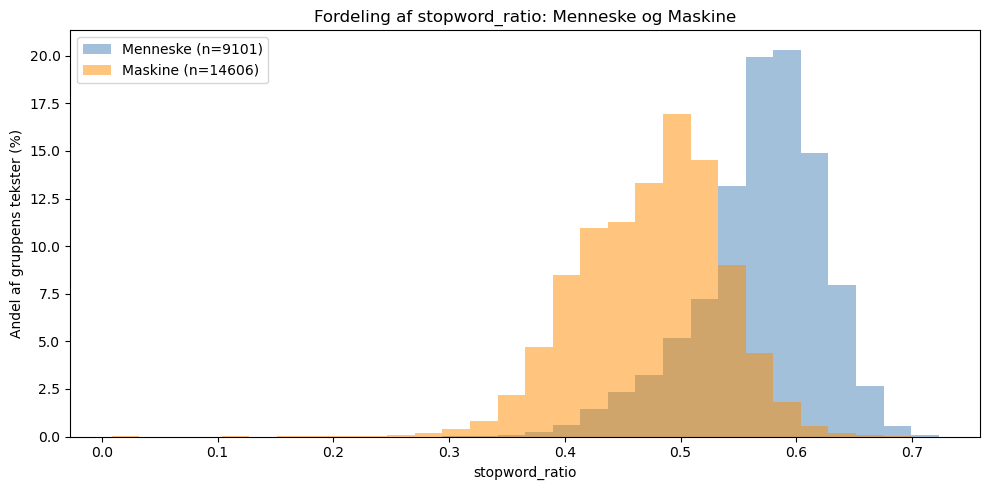

,Antal,Gennemsnit,Median,Standardafvigelse,Minimum,Maksimum,Antal_nuller,Nuller_procent
label,,,,,,,,
Menneske,9101,0.568992,0.576169,0.053794,0.311881,0.722877,0,0.0
Maskine,14606,0.473967,0.480730,0.060574,0.008532,0.694875,0,0.0


In [16]:
plot_feature_distribution(df, "stopword_ratio")



Statistik for punctuation_ratio:
label              Menneske    Maskine
Antal              9101.000  14606.000
Gennemsnit            0.152      0.133
Median                0.147      0.127
Standardafvigelse     0.038      0.032
Minimum               0.052      0.039
Maksimum              0.356      0.434
Antal_nuller          0.000      0.000
Nuller_procent        0.000      0.000


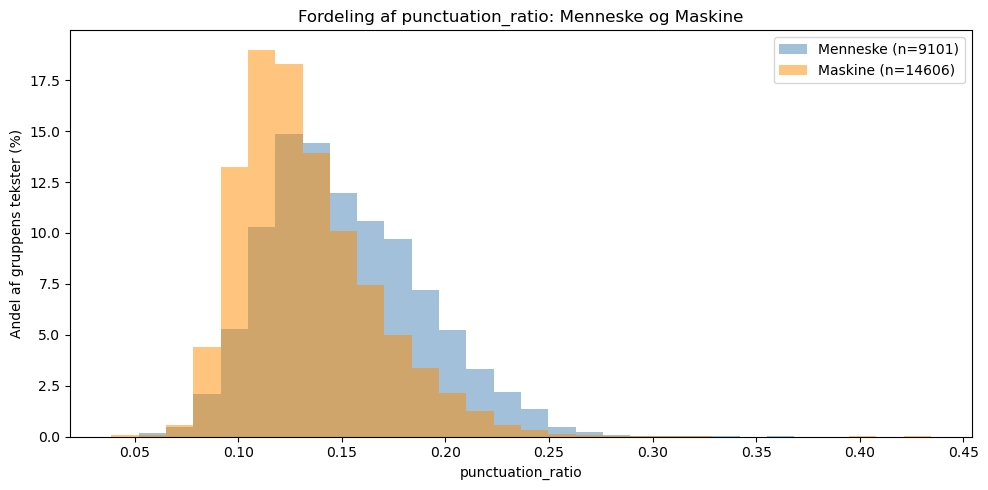

,Antal,Gennemsnit,Median,Standardafvigelse,Minimum,Maksimum,Antal_nuller,Nuller_procent
label,,,,,,,,
Menneske,9101,0.151957,0.146697,0.037723,0.052109,0.355698,0,0.0
Maskine,14606,0.132734,0.126748,0.032203,0.038685,0.434343,0,0.0


In [17]:
plot_feature_distribution(df, "punctuation_ratio")


Statistik for count_tokens:
label              Menneske    Maskine
Antal              9101.000  14606.000
Gennemsnit          318.936    311.428
Median              301.000    302.000
Standardafvigelse   114.509     95.238
Minimum              61.000     48.000
Maksimum           2429.000   1088.000
Antal_nuller          0.000      0.000
Nuller_procent        0.000      0.000


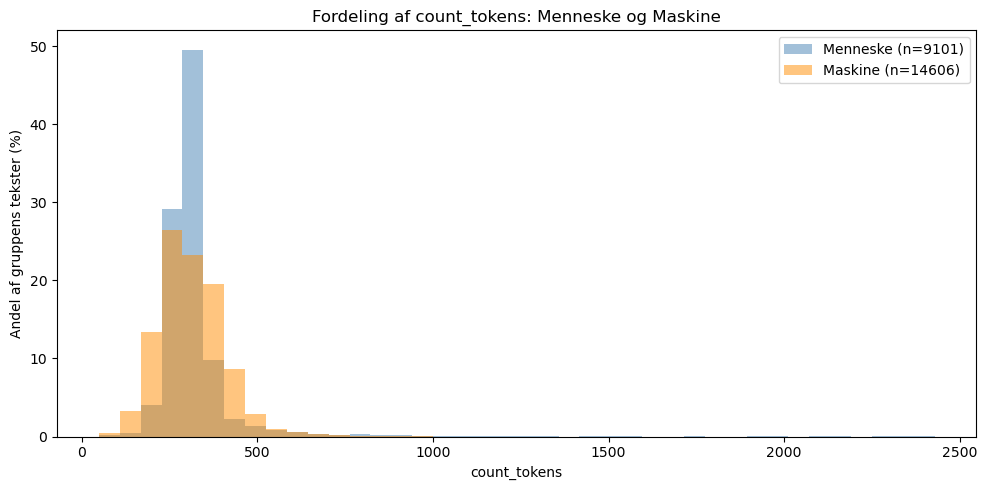

,Antal,Gennemsnit,Median,Standardafvigelse,Minimum,Maksimum,Antal_nuller,Nuller_procent
label,,,,,,,,
Menneske,9101,318.936051,301.0,114.508920,61,2429,0,0.0
Maskine,14606,311.427769,302.0,95.237595,48,1088,0,0.0


In [18]:
plot_feature_distribution(df, "count_tokens", bins=40)

In [81]:
df.head()

,id,text,model,label,genre,stopword_ratio,punctuation_ratio,count_characters,characters_per_token,count_tokens
0,ea468d03-1973-5039-86b2-ff225bb92c4e,"Duke Ellington, a titan of jazz, revolutionize...",falcon3-10b-instruct,1,essays,0.400545,0.132388,2480,5.862884,223
1,0d05f269-6d67-521d-9b5d-cc18f482c6c1,I reflected on the shifting dynamics of media ...,o3-mini,1,essays,0.439539,0.081129,3395,5.987654,295
2,c2ec79f3-da80-58f8-bef0-3e0ea7ab072f,"In F. Scott Fitzgerald's ""The Great Gatsby,"" t...",gpt-4o,1,essays,0.438356,0.105079,3288,5.758319,292
3,4ad37c58-0bb7-536b-997d-cfccabd0d094,I still chuckle when I think about that time I...,deepseek-r1-distill-qwen-32b,1,essays,0.564835,0.109589,2347,4.592955,201
4,07747b0c-5051-5e0d-8096-b4d4ed8bd98e,"Yoga, originating in ancient India, encompasse...",gemini-2.0-flash,1,essays,0.388258,0.159236,3588,5.713376,327


Beregner POS:   0%|          | 0/23707 [00:00<?, ?it/s]

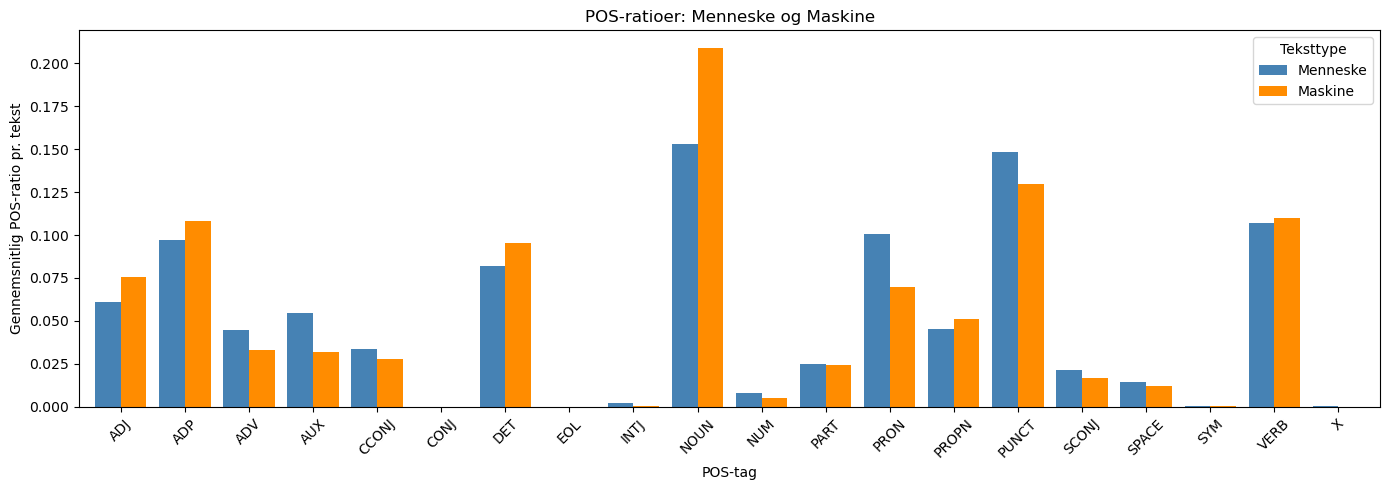

In [82]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from spacy.parts_of_speech import IDS
from tqdm.auto import tqdm

# Lav en separat kopi af de nødvendige kolonner
df_pos = df[["text", "label"]].copy()

# Alle navngivne POS-tags, inklusive dem med nul forekomster
pos_tags = sorted(tag for tag in IDS if tag)

pos_rows = []

docs = nlp.pipe(
    df_pos["text"],
    batch_size=128,
    disable=["ner", "lemmatizer"],
)

for doc in tqdm(docs, total=len(df_pos), desc="Beregner POS"):
    pos_rows.append(Counter(token.pos_ for token in doc))

# Én række pr. tekst og én kolonne pr. POS-tag
pos_counts = pd.DataFrame(pos_rows, index=df_pos.index)
pos_counts = pos_counts.reindex(
    columns=pos_tags,
    fill_value=0,
).fillna(0)

# Ratio pr. tekst: antal af POS-tagget / samlet antal tokens
token_totals = pos_counts.sum(axis=1).replace(0, float("nan"))
pos_ratios = pos_counts.div(token_totals, axis=0)

# Gennemsnit af teksternes ratioer for hver gruppe
group_means = pos_ratios.groupby(df_pos["label"]).mean()
group_means = group_means.reindex([0, 1]).rename(
    index={0: "Menneske", 1: "Maskine"}
)

# Søjlediagram
ax = group_means.T.plot(
    kind="bar",
    figsize=(14, 5),
    color=["steelblue", "darkorange"],
    width=0.8,
)

ax.set_xlabel("POS-tag")
ax.set_ylabel("Gennemsnitlig POS-ratio pr. tekst")
ax.set_title("POS-ratioer: Menneske og Maskine")
ax.legend(title="Teksttype")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Based on Figure of POS destribution - move forward with ADJ, ADP, ADV, AUX, DET, NOUN, PRON, Punct, 

Maybe only NOUN, PRON. (AUX?) 

In [19]:
import numpy as np
import pandas as pd
from collections import Counter
from spacy.parts_of_speech import IDS
from tqdm.auto import tqdm

def add_pos_ratios(df, pos_tags, text_column="text", batch_size=128):
    # Tillad både ét tag og en liste af tags
    if isinstance(pos_tags, str):
        pos_tags = [pos_tags]

    pos_tags = list(dict.fromkeys(tag.upper() for tag in pos_tags))

    if not pos_tags:
        raise ValueError("Vælg mindst ét POS-tag.")

    unknown_tags = set(pos_tags) - (set(IDS) - {""})
    if unknown_tags:
        raise ValueError(f"Ukendte POS-tags: {sorted(unknown_tags)}")

    result = df.copy()
    feature_rows = []

    docs = nlp.pipe(
        result[text_column],
        batch_size=batch_size,
        disable=["ner", "lemmatizer"],
    )

    for doc in tqdm(docs, total=len(result), desc="Beregner POS-ratioer"):
        counts = Counter(token.pos_ for token in doc)
        n_tokens = len(doc)

        feature_rows.append({
            f"pos_{tag}_ratio": (
                counts[tag] / n_tokens if n_tokens else np.nan
            )
            for tag in pos_tags
        })

    feature_columns = [f"pos_{tag}_ratio" for tag in pos_tags]

    features = pd.DataFrame(
        feature_rows,
        index=result.index,
        columns=feature_columns,
    )

    result[feature_columns] = features
    return result

In [21]:
dataset = add_pos_ratios(df, ["NOUN", "PRON", "AUX"])

Beregner POS-ratioer:   0%|          | 0/23707 [00:00<?, ?it/s]

In [22]:
dataset.head()

,id,text,model,label,genre,stopword_ratio,punctuation_ratio,count_characters,characters_per_token,count_tokens,pos_NOUN_ratio,pos_PRON_ratio,pos_AUX_ratio
0,ea468d03-1973-5039-86b2-ff225bb92c4e,"Duke Ellington, a titan of jazz, revolutionize...",falcon3-10b-instruct,1,essays,0.400545,0.132388,2480,5.862884,223,0.253521,0.049296,0.009390
1,0d05f269-6d67-521d-9b5d-cc18f482c6c1,I reflected on the shifting dynamics of media ...,o3-mini,1,essays,0.439539,0.081129,3395,5.987654,295,0.245614,0.064912,0.029825
2,c2ec79f3-da80-58f8-bef0-3e0ea7ab072f,"In F. Scott Fitzgerald's ""The Great Gatsby,"" t...",gpt-4o,1,essays,0.438356,0.105079,3288,5.758319,292,0.237847,0.043403,0.017361
3,4ad37c58-0bb7-536b-997d-cfccabd0d094,I still chuckle when I think about that time I...,deepseek-r1-distill-qwen-32b,1,essays,0.564835,0.109589,2347,4.592955,201,0.190661,0.116732,0.070039
4,07747b0c-5051-5e0d-8096-b4d4ed8bd98e,"Yoga, originating in ancient India, encompasse...",gemini-2.0-flash,1,essays,0.388258,0.159236,3588,5.713376,327,0.235759,0.023734,0.007911


## Model

Logistisk regression af features uden POS. (PolynominalFeatures)

In [23]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

# Find navnet på tegnsætningskolonnen
punctuation_feature = (
    "punctuation_ratio"
    if "punctuation_ratio" in dataset.columns
    else "punktuation_ratio"
)

# Kun disse fem features bruges
features = [
    "stopword_ratio",
    punctuation_feature,
    "count_characters",
    "characters_per_token",
    "count_tokens",
]

# Kontrollér, at de nødvendige kolonner findes
missing = [
    column
    for column in features + ["label"]
    if column not in dataset.columns
]

if missing:
    raise ValueError(f"Disse kolonner mangler i dataset: {missing}")

# Kopier features og labels
X = dataset[features].copy()
y = dataset["label"].copy()

if not y.isin([0, 1]).all() or y.nunique() != 2:
    raise ValueError("label skal indeholde begge grupper: 0 og 1, uden NaN.")

# Bevar omtrent samme klassefordeling i træning og test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

# Udfyld NaN med træningsmedianen, skalér og træn modellen
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42)),
])

logistic_model.fit(X_train, y_train)

# Forudsigelser på testdata
y_pred = logistic_model.predict(X_test)
y_probability = logistic_model.predict_proba(X_test)[:, 1]

# Evaluering
print(f"Træningstekster: {len(X_train)}")
print(f"Testtekster:    {len(X_test)}")
print(f"\nAccuracy:          {accuracy_score(y_test, y_pred):.3f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, y_probability):.3f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Menneske", "Maskine"],
    digits=3,
    zero_division=0,
))

print("Confusion matrix:")
print(pd.DataFrame(
    confusion_matrix(y_test, y_pred, labels=[0, 1]),
    index=["Faktisk Menneske", "Faktisk Maskine"],
    columns=["Forudsagt Menneske", "Forudsagt Maskine"],
))

Træningstekster: 18965
Testtekster:    4742

Accuracy:          0.829
Balanced accuracy: 0.815
ROC-AUC:           0.895

Classification report:
              precision    recall  f1-score   support

    Menneske      0.791     0.755     0.773      1820
     Maskine      0.852     0.875     0.863      2922

    accuracy                          0.829      4742
   macro avg      0.821     0.815     0.818      4742
weighted avg      0.828     0.829     0.829      4742

Confusion matrix:
                  Forudsagt Menneske  Forudsagt Maskine
Faktisk Menneske                1375                445
Faktisk Maskine                  364               2558


Logistisk regression af features uden POS. (PolynominalFeatures)

In [26]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

# Find navnet på tegnsætningskolonnen
punctuation_feature = (
    "punctuation_ratio"
    if "punctuation_ratio" in dataset.columns
    else "punktuation_ratio"
)

features = [
    "stopword_ratio",
    punctuation_feature,
    "count_characters",
    "characters_per_token",
    "count_tokens",
]

missing = [
    column
    for column in features + ["label"]
    if column not in dataset.columns
]

if missing:
    raise ValueError(f"Disse kolonner mangler i dataset: {missing}")

X = dataset[features].copy()
y = dataset["label"].copy()

if not y.isin([0, 1]).all() or y.nunique() != 2:
    raise ValueError("label skal indeholde begge grupper: 0 og 1, uden NaN.")

# Samme split-indstillinger som før
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

# count_tokens: udfyld NaN, og dan count_tokens samt count_tokens²
token_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median", keep_empty_features=True),
    ),
    (
        "poly",
        PolynomialFeatures(degree=2, include_bias=False),
    ),
])

# De øvrige features får ingen polynomial-transformation
other_features = [
    feature for feature in features
    if feature != "count_tokens"
]

preprocessor = ColumnTransformer([
    (
        "poly_tokens",
        token_transformer,
        ["count_tokens"],
    ),
    (
        "other_features",
        SimpleImputer(strategy="median", keep_empty_features=True),
        other_features,
    ),
])

# Skalér efter polynomial-transformationen
logistic_model_poly = Pipeline([
    ("features", preprocessor),
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42)),
])

logistic_model_poly.fit(X_train, y_train)

# Vis hvilke features modellen modtager
print("Transformerede features:")
print(logistic_model_poly.named_steps["features"].get_feature_names_out())

# Forudsigelser på testdata
y_pred_poly = logistic_model_poly.predict(X_test)
y_probability_poly = logistic_model_poly.predict_proba(X_test)[:, 1]

# Evaluering
print(f"\nTræningstekster: {len(X_train)}")
print(f"Testtekster:    {len(X_test)}")
print(f"\nAccuracy:          {accuracy_score(y_test, y_pred_poly):.3f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred_poly):.3f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, y_probability_poly):.3f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_poly,
    labels=[0, 1],
    target_names=["Menneske", "Maskine"],
    digits=3,
    zero_division=0,
))

print("Confusion matrix:")
print(pd.DataFrame(
    confusion_matrix(y_test, y_pred_poly, labels=[0, 1]),
    index=["Faktisk Menneske", "Faktisk Maskine"],
    columns=["Forudsagt Menneske", "Forudsagt Maskine"],
))

Transformerede features:
['poly_tokens__count_tokens' 'poly_tokens__count_tokens^2'
 'other_features__stopword_ratio' 'other_features__punctuation_ratio'
 'other_features__count_characters' 'other_features__characters_per_token']

Træningstekster: 18965
Testtekster:    4742

Accuracy:          0.829
Balanced accuracy: 0.816
ROC-AUC:           0.895

Classification report:
              precision    recall  f1-score   support

    Menneske      0.790     0.757     0.773      1820
     Maskine      0.852     0.875     0.863      2922

    accuracy                          0.829      4742
   macro avg      0.821     0.816     0.818      4742
weighted avg      0.828     0.829     0.829      4742

Confusion matrix:
                  Forudsagt Menneske  Forudsagt Maskine
Faktisk Menneske                1377                443
Faktisk Maskine                  366               2556


Logistisk regression af features med POS. ( uden PolynominalFeatures)

In [24]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

punctuation_feature = (
    "punctuation_ratio"
    if "punctuation_ratio" in dataset.columns
    else "punktuation_ratio"
)

# De oprindelige fem features
base_features = [
    "stopword_ratio",
    punctuation_feature,
    "count_characters",
    "characters_per_token",
    "count_tokens",
]

# Find eksisterende POS-ratioer
pos_features = sorted([
    column
    for column in dataset.columns
    if column.startswith("pos_") and column.endswith("_ratio")
])

if not pos_features:
    raise ValueError(
        "Ingen POS-ratiokolonner fundet i dataset. "
        "Tilføj først kolonner som fx pos_NOUN_ratio."
    )

features_with_pos = base_features + pos_features

missing = [
    column
    for column in features_with_pos + ["label"]
    if column not in dataset.columns
]

if missing:
    raise ValueError(f"Disse kolonner mangler i dataset: {missing}")

print("Features i modellen:")
print(features_with_pos)

# Kopier features og labels
X_pos = dataset[features_with_pos].copy()
y_pos = dataset["label"].copy()

if not y_pos.isin([0, 1]).all() or y_pos.nunique() != 2:
    raise ValueError("label skal indeholde begge grupper: 0 og 1, uden NaN.")

# Samme split-indstillinger som i modellen uden POS
X_train_pos, X_test_pos, y_train_pos, y_test_pos = train_test_split(
    X_pos,
    y_pos,
    test_size=0.20,
    random_state=42,
    stratify=y_pos,
)

logistic_model_pos = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42)),
])

logistic_model_pos.fit(X_train_pos, y_train_pos)

# Forudsigelser på testdata
y_pred_pos = logistic_model_pos.predict(X_test_pos)
y_probability_pos = logistic_model_pos.predict_proba(X_test_pos)[:, 1]

# Evaluering
print(f"\nTræningstekster: {len(X_train_pos)}")
print(f"Testtekster:    {len(X_test_pos)}")
print(f"\nAccuracy:          {accuracy_score(y_test_pos, y_pred_pos):.3f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test_pos, y_pred_pos):.3f}")
print(f"ROC-AUC:           {roc_auc_score(y_test_pos, y_probability_pos):.3f}")

print("\nClassification report:")
print(classification_report(
    y_test_pos,
    y_pred_pos,
    labels=[0, 1],
    target_names=["Menneske", "Maskine"],
    digits=3,
    zero_division=0,
))

print("Confusion matrix:")
print(pd.DataFrame(
    confusion_matrix(y_test_pos, y_pred_pos, labels=[0, 1]),
    index=["Faktisk Menneske", "Faktisk Maskine"],
    columns=["Forudsagt Menneske", "Forudsagt Maskine"],
))

Features i modellen:
['stopword_ratio', 'punctuation_ratio', 'count_characters', 'characters_per_token', 'count_tokens', 'pos_AUX_ratio', 'pos_NOUN_ratio', 'pos_PRON_ratio']

Træningstekster: 18965
Testtekster:    4742

Accuracy:          0.892
Balanced accuracy: 0.884
ROC-AUC:           0.951

Classification report:
              precision    recall  f1-score   support

    Menneske      0.867     0.850     0.858      1820
     Maskine      0.908     0.919     0.913      2922

    accuracy                          0.892      4742
   macro avg      0.887     0.884     0.886      4742
weighted avg      0.892     0.892     0.892      4742

Confusion matrix:
                  Forudsagt Menneske  Forudsagt Maskine
Faktisk Menneske                1547                273
Faktisk Maskine                  237               2685


# Test af med og uden token count

In [27]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
)

X = dataset[["count_tokens"]].copy()
y = dataset["label"].copy()

if not y.isin([0, 1]).all() or y.nunique() != 2:
    raise ValueError("label skal indeholde begge grupper: 0 og 1, uden NaN.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

model_tokens = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42)),
])

model_tokens.fit(X_train, y_train)

pred_tokens = model_tokens.predict(X_test)
prob_tokens = model_tokens.predict_proba(X_test)[:, 1]

scores_tokens = {
    "Accuracy": accuracy_score(y_test, pred_tokens),
    "Balanced accuracy": balanced_accuracy_score(y_test, pred_tokens),
    "ROC-AUC": roc_auc_score(y_test, prob_tokens),
}

# Baseline: gæt altid på den hyppigste klasse i træningsdata
majority_class = y_train.mode().iloc[0]
baseline_accuracy = (y_test == majority_class).mean()

print(f"Majoritetsbaseline, accuracy: {baseline_accuracy:.3f}")
print("\nKun count_tokens:")
print(pd.Series(scores_tokens).round(3).to_string())

Majoritetsbaseline, accuracy: 0.616

Kun count_tokens:
Accuracy             0.618
Balanced accuracy    0.502
ROC-AUC              0.519


In [28]:
from sklearn.preprocessing import PolynomialFeatures

model_tokens_poly = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42)),
])

model_tokens_poly.fit(X_train, y_train)

pred_tokens_poly = model_tokens_poly.predict(X_test)
prob_tokens_poly = model_tokens_poly.predict_proba(X_test)[:, 1]

scores_tokens_poly = {
    "Accuracy": accuracy_score(y_test, pred_tokens_poly),
    "Balanced accuracy": balanced_accuracy_score(y_test, pred_tokens_poly),
    "ROC-AUC": roc_auc_score(y_test, prob_tokens_poly),
}

# Sammenlign de to modeller
comparison = pd.DataFrame(
    [scores_tokens, scores_tokens_poly],
    index=[
        "Kun count_tokens",
        "count_tokens + count_tokens²",
    ],
)

print("\nSammenligning:")
print(comparison.round(3).to_string())


Sammenligning:
                              Accuracy  Balanced accuracy  ROC-AUC
Kun count_tokens                 0.618              0.502    0.519
count_tokens + count_tokens²     0.618              0.503    0.519


## Extrinsic evaluation

## Intrinsic evaluation